## Crop Filtering TEMPO ##

lowCF, all hours version 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

In [2]:
crop_mask = '/global/scratch/users/rubypercival/MODIS24/0.1x0.1_cropland_mask_MCD12Q1'
crop_df= pd.read_parquet(crop_mask, engine='pyarrow')

In [3]:
crop_df

,grid_lat,grid_lon,is_majority_cropland
11,36.05,-102.85,True
12,36.05,-102.75,True
13,36.05,-102.65,True
14,36.05,-102.55,True
15,36.05,-102.45,True
...,...,...,...
31028,48.95,-97.15,True
31029,48.95,-97.05,True
31030,48.95,-96.95,True
31031,48.95,-96.85,True


In [4]:
cropland_only = crop_df[crop_df['is_majority_cropland'] == True]

In [5]:
tempo_file= '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/lowCF_TEMPO_0.1x0.1_gridded_mar-jul24_V04.parquet'
no2_df=pd.read_parquet(tempo_file, engine='pyarrow')


In [6]:
no2_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,no2_sem,cv_no2
0,2024-04-28 13:36:38.029074,36.05,-80.55,9.598033e+14,4.405143e+14,25,0.024594,0.003001,0.123984,0.013526,0.0,0.0,8.810287e+13,0.458963
1,2024-04-28 13:36:38.029074,36.35,-101.65,1.522695e+15,5.267550e+14,25,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.053510e+14,0.345936
3,2024-04-28 13:36:38.029074,36.65,-87.15,1.771678e+15,4.801409e+14,25,0.023199,0.003127,0.103296,0.012250,0.0,0.0,9.602818e+13,0.271009
4,2024-04-28 13:36:38.029074,36.65,-82.35,1.508406e+15,5.445526e+14,25,0.014841,0.005620,0.077634,0.025346,0.0,0.0,1.089105e+14,0.361012
5,2024-04-28 13:36:38.029074,36.75,-102.85,9.376960e+14,3.519136e+14,25,0.000000,0.000000,0.000000,0.000000,0.0,0.0,7.038271e+13,0.375296
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25842837,2024-06-14 14:40:49.026964,48.25,-101.35,2.231522e+15,9.046172e+14,25,0.005159,0.005767,0.020274,0.022322,0.0,0.0,1.809234e+14,0.405381
25842838,2024-06-14 14:40:49.026964,48.25,-93.15,5.126158e+14,6.263508e+14,16,0.002181,0.003955,0.010286,0.018282,0.0,0.0,1.565877e+14,1.221872
25842839,2024-06-14 14:40:49.026964,48.35,-94.45,1.068936e+15,7.929801e+14,15,0.024599,0.011901,0.101435,0.045092,0.0,0.0,2.047466e+14,0.741841
25842840,2024-06-14 14:40:49.026964,48.45,-99.45,1.285680e+15,6.510088e+14,25,0.008919,0.003305,0.036196,0.012992,0.0,0.0,1.302018e+14,0.506354


In [7]:
grid_res = 0.02

no2_df['grid_lat'] = no2_df['grid_lat'].astype('float64').round(2)
no2_df['grid_lon'] = no2_df['grid_lon'].astype('float64').round(2)
cropland_only['grid_lat'] = cropland_only['grid_lat'].astype('float64').round(2)
cropland_only['grid_lon'] = cropland_only['grid_lon'].astype('float64').round(2)

no2_cropland = pd.merge(no2_df, cropland_only[['grid_lat', 'grid_lon']], on=['grid_lat', 'grid_lon'], how='inner')
print('Cropland cells matched:', no2_cropland[['grid_lat','grid_lon']].drop_duplicates().shape[0])


Cropland cells matched: 10995


In [8]:
no2_cropland

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,no2_sem,cv_no2
0,2024-04-28 13:36:38.029074,36.65,-87.15,1.771678e+15,4.801409e+14,25,0.023199,0.003127,0.103296,0.012250,0.0,0.0,9.602818e+13,0.271009
1,2024-04-28 13:36:38.029074,39.55,-83.55,1.186191e+15,4.130454e+14,25,0.038394,0.002605,0.151425,0.009300,0.0,0.0,8.260908e+13,0.348211
2,2024-04-28 13:36:38.029074,40.05,-83.25,8.659782e+14,3.557714e+14,25,0.054323,0.006920,0.205064,0.020988,0.0,0.0,7.115428e+13,0.410832
3,2024-04-28 13:36:38.029074,40.15,-84.45,1.078595e+15,3.651905e+14,25,0.080760,0.007300,0.279474,0.020868,0.0,0.0,7.303811e+13,0.338580
4,2024-04-28 14:36:38.023916,36.15,-102.45,1.131316e+15,3.384887e+14,25,0.000117,0.000276,0.000495,0.001165,0.0,0.0,6.769773e+13,0.299199
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7717614,2024-06-14 14:40:49.026964,45.95,-97.25,1.817754e+15,8.948690e+14,24,0.003454,0.002283,0.015408,0.010124,0.0,0.0,1.826644e+14,0.492294
7717615,2024-06-14 14:40:49.026964,46.85,-100.35,1.637446e+15,6.149652e+14,25,0.006333,0.005117,0.026397,0.020767,0.0,0.0,1.229930e+14,0.375564
7717616,2024-06-14 14:40:49.026964,47.65,-98.45,1.431446e+15,8.585968e+14,25,0.004507,0.002653,0.019418,0.011241,0.0,0.0,1.717194e+14,0.599811
7717617,2024-06-14 14:40:49.026964,48.25,-101.35,2.231522e+15,9.046172e+14,25,0.005159,0.005767,0.020274,0.022322,0.0,0.0,1.809234e+14,0.405381


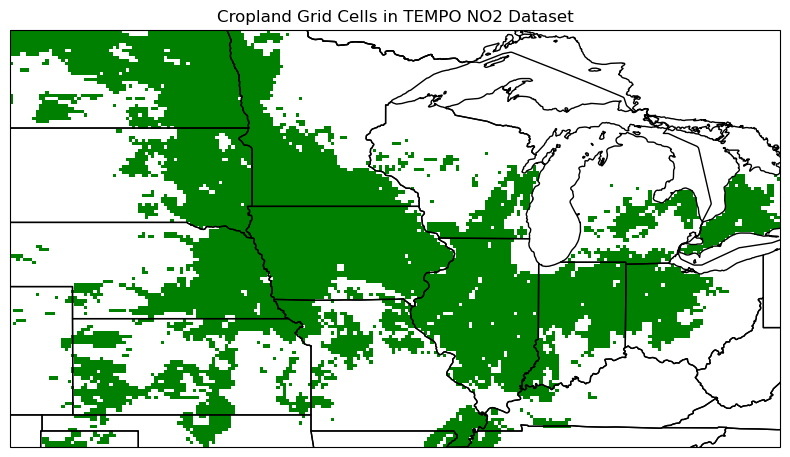

In [9]:
cropland_points = no2_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in cropland_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='green',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('Cropland Grid Cells in TEMPO NO2 Dataset')
plt.tight_layout()
plt.show()

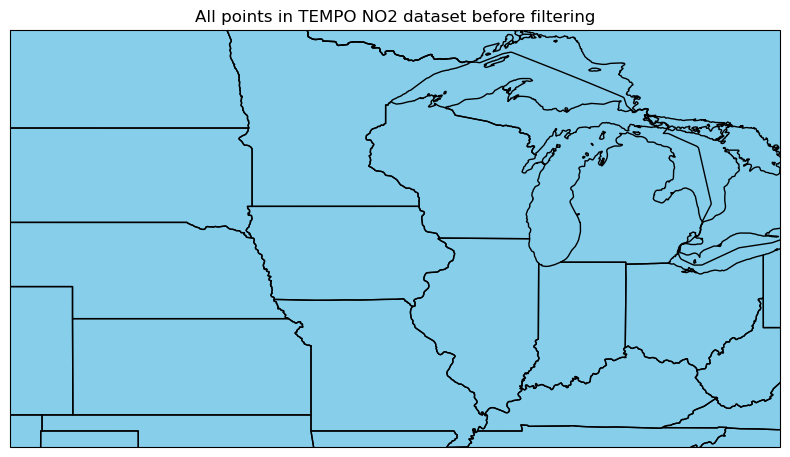

In [10]:
no2_points = no2_df[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in no2_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom-left corner coord
        0.1, 0.1, #width and height in degrees 
        facecolor='skyblue',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title('All points in TEMPO NO2 dataset before filtering')
plt.tight_layout()
plt.show()

In [11]:
output = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/lowCF_TEMPO_03-07_0.1x0.1GCF_V04_MCD12Q1mask_2024.parquet'
no2_cropland.to_parquet(output, engine='pyarrow')
print('Saved to:', output)

Saved to: /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/lowCF_TEMPO_03-07_0.1x0.1GCF_V04_MCD12Q1mask_2024.parquet
